# Phase 3 — Bivariate and Multivariate Analysis
## Patterns of Recorded Civilian Targeting in Gaza

**DS312 · Group 7 · Phase 3 EDA, bivariate and multivariate section**

> **Assumption note.** We read the leader's "at least 8 visualizations" as the target for *this* section alone, because the guide counts 8 charts for the whole phase and we cannot see what teammates are covering. This section therefore has 11 charts. If teammates already cover the same ground, the safest charts to drop are Charts 1 and 2 (they use the same tables as Hypotheses A and B) and Chart 9 (if the weekly trend is assigned elsewhere). Dropping them still leaves 8 or more. Hypothesis tests, the key-insights list and the Phase 4 plan are **not** in this notebook; they belong to other members.

## 1. Introduction

### Purpose and scope
This section looks at how recorded Gaza events relate to each other: how the focal share changes between periods, event types, precision levels, districts and weeks, and how fatalities differ between groups. It supports the Phase 1 business questions BQ1 (before/after), BQ2 (event and actor profiles), BQ4 (district-week concentration and persistence) and BQ5 (sensitivity to precision), and it tests whether the Phase 4 plan (weekly anomaly detection at district level) has enough structure to work with.

### Which table answers which question

| Question | Table (unit of analysis) | Charts |
|---|---|---|
| Before/after focal share; event-type mix and prevalence; fatalities; precision; actors | `acled_events_clean.csv` (one Gaza event) | 1 to 7 |
| Where and when focal activity is concentrated by district | `acled_district_week.csv` (one known district and week) | 8 and 10 |
| How Gaza-wide weekly counts and shares move | `acled_gaza_week.csv` (one Gaza-wide week) | 9 and 11 (left) |
| Which categorical fields are associated | `acled_events_clean.csv`, political-violence records only | 11 (right) |

We do not mix units. Event-level results are never added to weekly results without an explicit aggregation step.

### Interpretation boundaries
- We describe **recorded ACLED events** and the project's own focal-event rule (ACLED targeting flag **and** the exact label "Civilians (Palestine)" in either actor field). The rule is a reproducible coding convention, not proof of intent, responsibility or legal classification.
- **Focal share** always means focal events divided by political-violence records from the *same* group, area and period. Counts are shown next to every rate.
- A zero in these tables means zero **recorded** events or fatalities. It is not evidence that no harm occurred, and a zero fatality count can also mean that no fatality information was reported.
- Associations are exploratory. Events are related across time and place, so neither the correlations nor the group differences should be read as causal.

## 2. Setup and data loading

We load the four Phase 2 outputs from `data/processed/`, parse dates, and restore the two precision codes as ordered categories (CSV does not keep dtypes). The focal-incident file is not needed here because spatial work belongs to another section.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle
import seaborn as sns
from scipy.stats import chi2_contingency
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "axes.labelsize": 10, "legend.fontsize": 9})

SEED = 42  # no resampling is used in this section; fixed anyway so reruns are identical
np.random.seed(SEED)
plt.rcParams["axes.grid.axis"] = "y"  # horizontal gridlines only; heatmaps and horizontal bars adjust below

# Colours reused across charts: focal = dark red, other/non-focal = blue, context = grey
C_FOCAL, C_OTHER, C_GREY = "#8D3B42", "#315A7D", "#9AA5B1"

In [2]:
def find_data_dir(filename="acled_events_clean.csv"):
    """Look for data/processed/ in the working folder and its parents."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        candidate = base / "data" / "processed"
        if (candidate / filename).is_file():
            return candidate
    raise FileNotFoundError("Could not find data/processed/. Run this notebook from the project "
                            "folder that contains data/processed/.")

DATA_DIR = find_data_dir()
print("Reading Phase 2 outputs from:", DATA_DIR.resolve())

# Event-level master (Gaza, Jan 2022 to Sep 2025)
master = pd.read_csv(DATA_DIR / "acled_events_clean.csv",
                     parse_dates=["event_date", "month_start", "week_start"])
for col in ("geo_precision", "time_precision"):
    master[col] = pd.Categorical(master[col], categories=[1, 2, 3], ordered=True)

# Weekly tables (Oct 7, 2023 onward)
gaza_week = pd.read_csv(DATA_DIR / "acled_gaza_week.csv", parse_dates=["week_start", "week_end"])
district_week = pd.read_csv(DATA_DIR / "acled_district_week.csv", parse_dates=["week_start", "week_end"])

print("master:", master.shape, "| gaza_week:", gaza_week.shape, "| district_week:", district_week.shape)

Reading Phase 2 outputs from: /home/claude/project/data/processed


master: (26664, 43) | gaza_week: (104, 13) | district_week: (520, 14)


In [3]:
# Period definitions follow Phase 2: Oct 7, 2023 is the cut-off; the two periods differ in length.
BEFORE, AFTER = "Before Oct 7, 2023", "Oct 7, 2023 onward"
COVERAGE_START, CUTOFF, COVERAGE_END = pd.Timestamp("2022-01-01"), pd.Timestamp("2023-10-07"), pd.Timestamp("2025-09-30")
PERIOD_DAYS = {BEFORE: (CUTOFF - COVERAGE_START).days, AFTER: (COVERAGE_END - CUTOFF).days + 1}

# Political-violence records are the denominator for every focal share in this notebook
political = master.loc[master.political_violence].copy()

# Integrity check: compare what we loaded with the figures documented in Phase 2.
checks = pd.DataFrame([
    ("Event master shape", (26664, 43), master.shape),
    ("Gaza-week table shape", (104, 13), gaza_week.shape),
    ("District-week table shape", (520, 14), district_week.shape),
    ("Focal events, all", 10714, int(master.focal_event.sum())),
    ("Focal events before Oct 7", 63, int(master.loc[master.period == BEFORE, "focal_event"].sum())),
    ("Focal events Oct 7 onward", 10651, int(master.loc[master.period == AFTER, "focal_event"].sum())),
    ("Political-violence records before Oct 7", 389, int((political.period == BEFORE).sum())),
    ("Political-violence records Oct 7 onward", 22364, int((political.period == AFTER).sum())),
    ("Focal events outside political violence", 0, int((master.focal_event & ~master.political_violence).sum())),
    ("Events with no district", 4, int(master.admin2.isna().sum())),
    ("Gaza-week focal total", 10651, int(gaza_week.focal_events.sum())),
    ("District-week focal total (3 focal events lack a district)", 10648, int(district_week.focal_events.sum())),
    ("Incomplete weeks in Gaza-week table", 1, int((~gaza_week.complete_week).sum())),
    ("Duplicate district-week keys", 0, int(district_week.duplicated(["admin2", "week_start"]).sum())),
], columns=["Check", "Expected (Phase 2)", "Observed"])
checks["Match"] = [e == o for e, o in zip(checks["Expected (Phase 2)"], checks["Observed"])]
display(checks)
print("All checks match Phase 2." if checks.Match.all() else "Some checks differ: review the table above before using the results.")
print("Incomplete week:", gaza_week.loc[~gaza_week.complete_week, "week_start"].dt.date.tolist(),
      "(week ends after the Sep 30, 2025 export boundary)")

,Check,Expected (Phase 2),Observed,Match
0,Event master shape,"(26664, 43)","(26664, 43)",True
1,Gaza-week table shape,"(104, 13)","(104, 13)",True
2,District-week table shape,"(520, 14)","(520, 14)",True
3,"Focal events, all",10714,10714,True
4,Focal events before Oct 7,63,63,True
5,Focal events Oct 7 onward,10651,10651,True
6,Political-violence records before Oct 7,389,389,True
7,Political-violence records Oct 7 onward,22364,22364,True
8,Focal events outside political violence,0,0,True
9,Events with no district,4,4,True


All checks match Phase 2.
Incomplete week: [datetime.date(2025, 9, 27)] (week ends after the Sep 30, 2025 export boundary)


## 3. Bivariate analysis

Source table for this section: `master` (political-violence records unless stated). Every share names its numerator and denominator.

### 3.1 Focal share before vs. after October 7, 2023 (BQ1)

**Question.** Does the focal share of political-violence records differ between the two periods? The periods are 644 and 725 days long, and the earlier one is sparse, so the chart pairs the share with per-week rates.

,political_records,focal,not_focal,focal_share,calendar_days,focal_per_week,political_per_week
period,,,,,,,
"Before Oct 7, 2023",389,63,326,0.162,644,0.68,4.23
"Oct 7, 2023 onward",22364,10651,11713,0.476,725,102.84,215.93


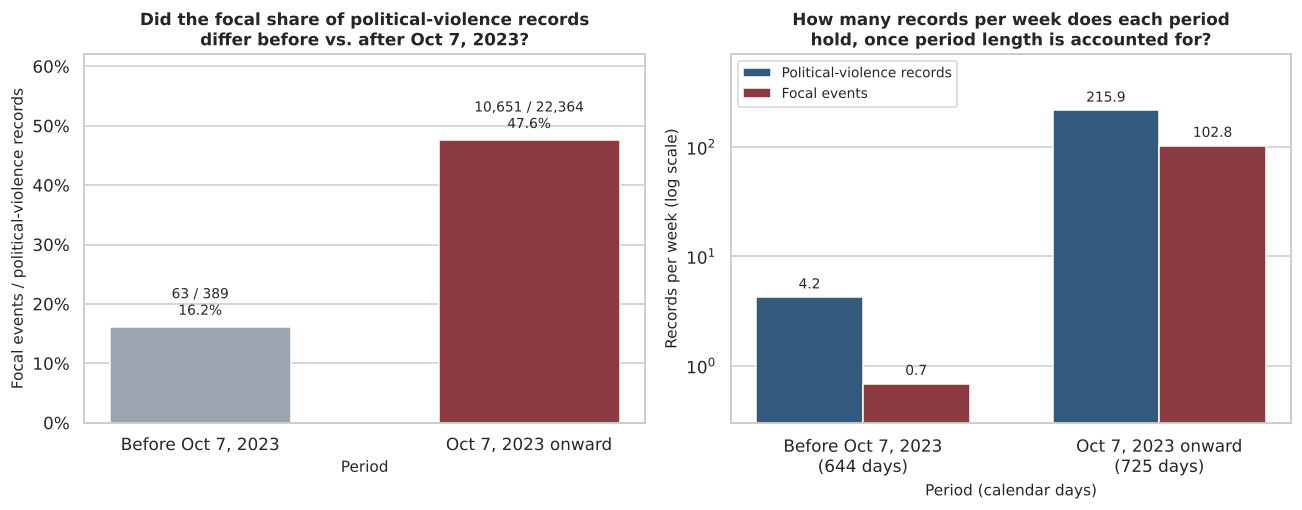

In [4]:
t1 = (political.groupby("period")
      .agg(political_records=("event_id_cnty", "size"), focal=("focal_event", "sum"))
      .loc[[BEFORE, AFTER]])
t1["not_focal"] = t1.political_records - t1.focal
t1["focal_share"] = t1.focal / t1.political_records
t1["calendar_days"] = [PERIOD_DAYS[p] for p in t1.index]
t1["focal_per_week"] = t1.focal * 7 / t1.calendar_days
t1["political_per_week"] = t1.political_records * 7 / t1.calendar_days
display(t1.round({"focal_share": 3, "focal_per_week": 2, "political_per_week": 2}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Left: focal share with numerator/denominator written on each bar
ax = axes[0]
bars = ax.bar(t1.index, t1.focal_share, color=[C_GREY, C_FOCAL], width=0.55)
for b, (_, r) in zip(bars, t1.iterrows()):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.012,
            f"{r.focal:,.0f} / {r.political_records:,.0f}\n{r.focal_share:.1%}", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, 0.62)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylabel("Focal events / political-violence records")
ax.set_xlabel("Period")
ax.set_title("Did the focal share of political-violence records\ndiffer before vs. after Oct 7, 2023?")

# Right: per-week rates (log scale because the two periods differ by about 150x)
ax = axes[1]
x = np.arange(len(t1)); w = 0.36
b1 = ax.bar(x - w / 2, t1.political_per_week, w, color=C_OTHER, label="Political-violence records")
b2 = ax.bar(x + w / 2, t1.focal_per_week, w, color=C_FOCAL, label="Focal events")
for bars_, vals in ((b1, t1.political_per_week), (b2, t1.focal_per_week)):
    for b, v in zip(bars_, vals):
        ax.text(b.get_x() + b.get_width() / 2, v * 1.12, f"{v:,.1f}", ha="center", va="bottom", fontsize=9)
ax.set_yscale("log"); ax.set_ylim(0.3, 700)
ax.set_xticks(x)
ax.set_xticklabels([f"{p}\n({PERIOD_DAYS[p]} days)" for p in t1.index])
ax.set_xlabel("Period (calendar days)")
ax.set_ylabel("Records per week (log scale)")
ax.set_title("How many records per week does each period\nhold, once period length is accounted for?")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Interpretation.** The focal share is 16.2% (63 of 389 records) before Oct 7, 2023 and 47.6% (10,651 of 22,364) from Oct 7 onward, and the weekly rate of focal events goes from about 0.7 to about 102.8 across periods of 644 and 725 days (BQ1). The earlier period rests on only 63 focal events, so its share is imprecise, and a difference in share alone cannot separate a change in events from a change in coding or reporting coverage.

### 3.2 Focal prevalence within each event type (BQ2)

**Question.** Within each recorded event type, what share of political-violence records meet the focal rule? Counts alone would mostly show which types are large, so each bar uses its own type's denominator. Groups with fewer than 30 records are hatched.

,n,focal,focal_share
event_type,,,
Battles,1648,0,0.0000
Protests,7,0,0.0000
Riots,8,0,0.0000
Explosions/Remote violence,20276,9906,0.4886
Violence against civilians,814,808,0.9926


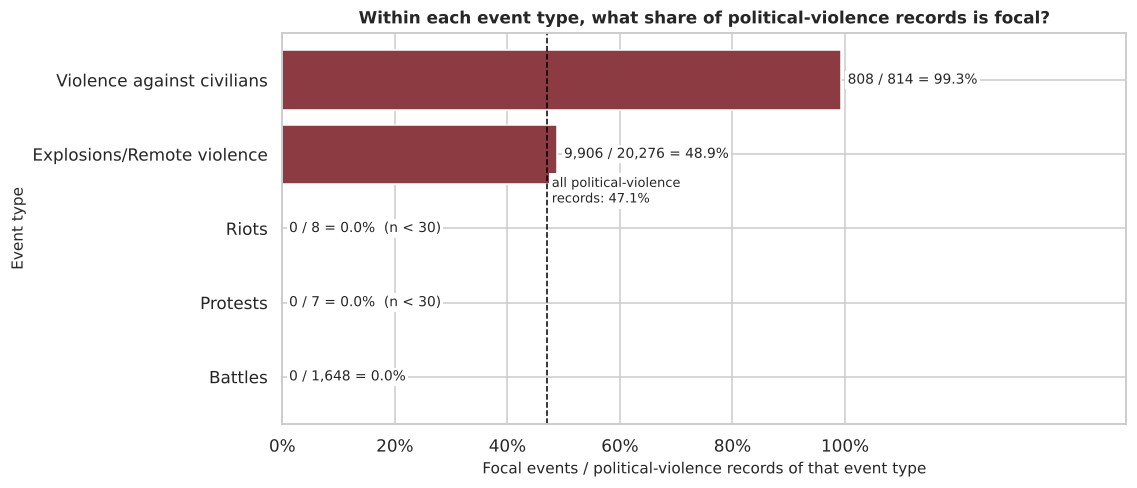

In [5]:
t2 = (political.groupby("event_type")
      .agg(n=("event_id_cnty", "size"), focal=("focal_event", "sum")))
t2["focal_share"] = t2.focal / t2.n
t2 = t2.sort_values("focal_share")
overall_share = political.focal_event.mean()
display(t2.round({"focal_share": 4}))

fig, ax = plt.subplots(figsize=(10.5, 4.6))
small = (t2.n < 30).to_numpy()
bars = ax.barh(t2.index, t2.focal_share, color=[C_GREY if s else C_FOCAL for s in small])
for b, s in zip(bars, small):
    if s:
        b.set_hatch("//")
for y, (_, r) in enumerate(t2.iterrows()):
    note = "  (n < 30)" if r.n < 30 else ""
    ax.text(r.focal_share + 0.012, y, f"{r.focal:,.0f} / {r.n:,.0f} = {r.focal_share:.1%}{note}", va="center", fontsize=9,
            bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
ax.axvline(overall_share, color="black", ls="--", lw=1)
ax.text(overall_share + 0.008, 2.5, f"all political-violence\nrecords: {overall_share:.1%}", fontsize=8.5, va="center",
        bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
ax.grid(axis="x")
ax.set_xlim(0, 1.5); ax.set_xticks(np.arange(0, 1.01, 0.2))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Focal events / political-violence records of that event type")
ax.set_ylabel("Event type")
ax.set_title("Within each event type, what share of political-violence records is focal?")
plt.tight_layout()
plt.show()

**Interpretation.** Violence against civilians is almost entirely focal (808 of 814, 99.3%), Explosions/Remote violence is split (9,906 of 20,276, 48.9%), Battles have none (0 of 1,648), and Protests and Riots (7 and 8 records) have none (BQ2). The focal rule requires a civilian actor label, so part of this pattern is built into the coding; it describes how focal events are recorded, not which event types produce them, and the two small types cannot be judged.

### 3.3 Fatalities by focal status (BQ2)

**Question.** Do focal records report more fatalities than other political-violence records? Fatalities are heavily skewed with many zeros, so we compare full distributions (ECDF on a symmetric-log axis) and report median, IQR and percentiles instead of means alone. Fatalities are reported event totals, not civilian-death counts.

Political-violence records, by focal status


,n,share_zero,median,q1,q3,p90,mean,max
focal_event,,,,,,,,
False,12039,0.86,0.0,0.0,0.0,2.0,1.31,150
True,10714,0.31,2.0,0.0,5.0,12.0,4.87,471


Same comparison split by period


n  share_zero  median   q1   q3   p90  \
period             focal_event                                              
Before Oct 7, 2023 False          326        0.93     0.0  0.0  0.0   0.0   
                   True            63        0.78     0.0  0.0  0.0   2.0   
Oct 7, 2023 onward False        11713        0.86     0.0  0.0  0.0   3.0   
                   True         10651        0.31     2.0  0.0  5.0  12.0   

                                mean  max  
period             focal_event             
Before Oct 7, 2023 False        0.17    8  
                   True         0.59    7  
Oct 7, 2023 onward False        1.34  150  
                   True         4.90  471

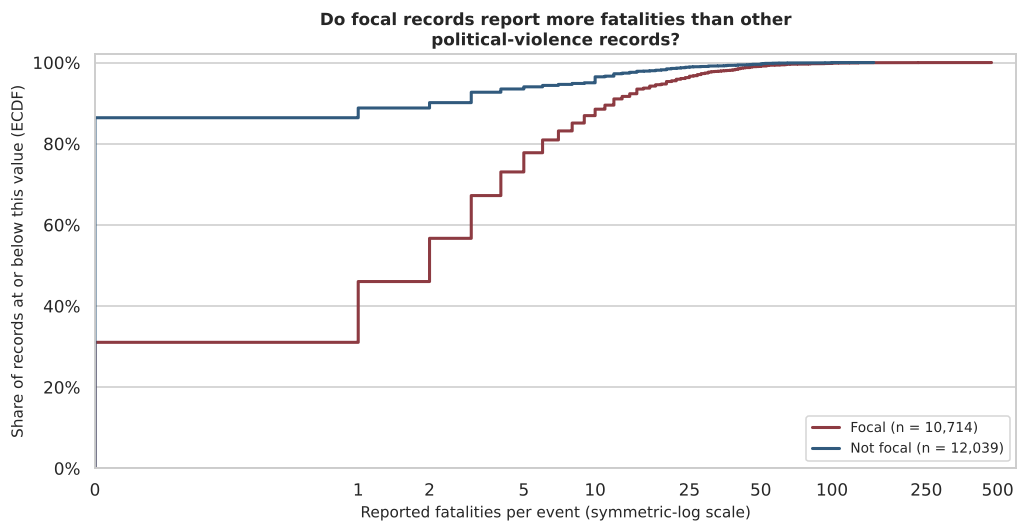

In [6]:
def fatality_summary(df, by):
    g = df.groupby(by, observed=True).fatalities
    return pd.DataFrame({"n": g.size(), "share_zero": g.apply(lambda s: (s == 0).mean()),
                         "median": g.median(), "q1": g.quantile(0.25), "q3": g.quantile(0.75),
                         "p90": g.quantile(0.90), "mean": g.mean(), "max": g.max()})

print("Political-violence records, by focal status")
display(fatality_summary(political, "focal_event").round(2))
print("Same comparison split by period")
display(fatality_summary(political, ["period", "focal_event"]).round(2))

fig, ax = plt.subplots(figsize=(9.5, 5))
for flag, label, col in [(True, "Focal", C_FOCAL), (False, "Not focal", C_OTHER)]:
    v = np.sort(political.loc[political.focal_event == flag, "fatalities"].to_numpy())
    ax.step(v, np.arange(1, len(v) + 1) / len(v), where="post", color=col, lw=2, label=f"{label} (n = {len(v):,})")
ax.set_xscale("symlog", linthresh=1)
ticks = [0, 1, 2, 5, 10, 25, 50, 100, 250, 500]
ax.set_xticks(ticks); ax.set_xticklabels([str(t) for t in ticks]); ax.minorticks_off()
ax.set_xlim(0, 600); ax.set_ylim(0, 1.02)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Reported fatalities per event (symmetric-log scale)")
ax.set_ylabel("Share of records at or below this value (ECDF)")
ax.set_title("Do focal records report more fatalities than other\npolitical-violence records?")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Interpretation.** Focal records report fatalities more often and in larger amounts: 31% report zero fatalities against 86% of other political-violence records, and the median is 2 against 0 (90th percentile 12 against 2). The gap is clear from Oct 7 onward (focal median 2, non-focal 0), while before Oct 7 both medians are 0 and only 63 records are focal (BQ2); fatalities are reported event totals, not confirmed civilian deaths, and a zero can mean that no fatality figure was recorded.

### 3.4 Fatalities by event type and focal status (BQ2)

**Question.** Because more than half of all records report zero fatalities, one number cannot describe severity. The left panel shows how often a group reports at least one fatality; the right panel shows how large the reported totals are among records that report at least one. Groups with fewer than 30 records are left out of the chart and kept in the table.

,n,share_with_fatality,events_with_fatality,median_if_any,q1_if_any,q3_if_any,max,shown_in_chart
group,,,,,,,,
Explosions · not focal,10370,0.084,874,3.0,2.0,9.0,100,True
Explosions · focal,9906,0.693,6869,3.0,2.0,8.0,471,True
Battles · not focal,1648,0.461,760,10.0,3.0,13.0,150,True
Violence vs. civilians · focal,808,0.642,519,2.0,1.0,6.0,118,True
Riots · not focal,8,0.125,1,2.0,2.0,2.0,2,False
Protests · not focal,7,0.000,0,NaN,NaN,NaN,0,False
Violence vs. civilians · not focal,6,0.500,3,1.0,1.0,3.5,6,False


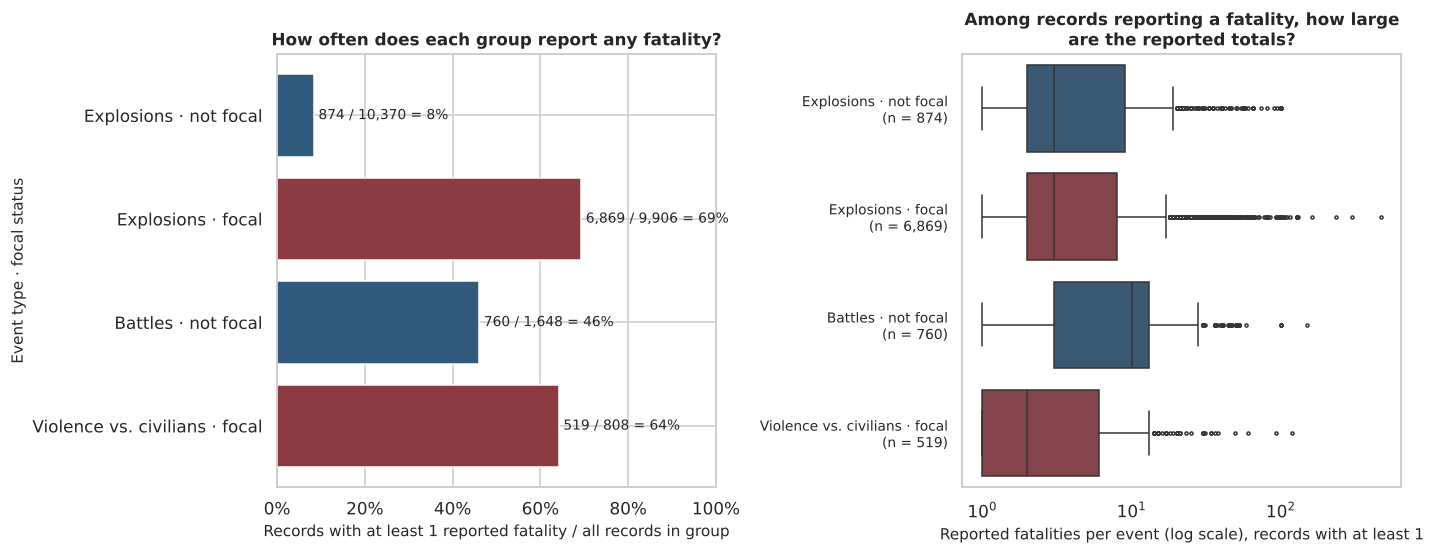

In [7]:
short = {"Explosions/Remote violence": "Explosions", "Violence against civilians": "Violence vs. civilians"}
political["group"] = (political.event_type.map(lambda t: short.get(t, t))
                      + np.where(political.focal_event, " · focal", " · not focal"))

g5 = political.groupby("group").fatalities
t5 = pd.DataFrame({"n": g5.size(), "share_with_fatality": g5.apply(lambda s: (s > 0).mean()),
                   "events_with_fatality": g5.apply(lambda s: (s > 0).sum()),
                   "median_if_any": g5.apply(lambda s: s[s > 0].median()),
                   "q1_if_any": g5.apply(lambda s: s[s > 0].quantile(0.25)),
                   "q3_if_any": g5.apply(lambda s: s[s > 0].quantile(0.75)),
                   "max": g5.max()}).sort_values("n", ascending=False)
t5["shown_in_chart"] = t5.n >= 30
display(t5.round(3))

order = [g for g in t5.index[t5.n >= 30]]
palette5 = {g: (C_FOCAL if g.endswith("· focal") else C_OTHER) for g in order}
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

ax = axes[0]
vals = t5.loc[order, "share_with_fatality"]
bars = ax.barh(order, vals, color=[palette5[g] for g in order])
for y, g in enumerate(order):
    r = t5.loc[g]
    ax.text(r.share_with_fatality + 0.01, y, f"{r.events_with_fatality:,.0f} / {r.n:,.0f} = {r.share_with_fatality:.0%}", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, 1.0); ax.grid(axis="x")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Records with at least 1 reported fatality / all records in group")
ax.set_ylabel("Event type · focal status")
ax.set_title("How often does each group report any fatality?")

ax = axes[1]
sub = political[political.group.isin(order) & (political.fatalities > 0)]
sns.boxplot(data=sub, x="fatalities", y="group", hue="group", order=order, hue_order=order,
            palette=palette5, legend=False, orient="h", fliersize=2, linewidth=1, ax=ax)
ax.set_xscale("log")
ax.set_yticks(range(len(order)))
ax.set_yticklabels([f"{g}\n(n = {int((sub.group == g).sum()):,})" for g in order], fontsize=9)
ax.set_xlabel("Reported fatalities per event (log scale), records with at least 1")
ax.set_ylabel("")
ax.set_title("Among records reporting a fatality, how large\nare the reported totals?")
plt.tight_layout()
plt.show()

**Interpretation.** Within Explosions, 69% of focal records (6,869 of 9,906) report at least one fatality against 8% of non-focal ones (874 of 10,370), yet among records that do report a fatality the typical total is the same (median 3 in both); Battles have the largest typical totals (median 10, n = 760) and Violence against civilians the smallest (median 2, n = 519) (BQ2). So the focal group differs mainly in how often a fatality is reported rather than in how large it is, and every comparison depends on whether a fatality was recorded at all.

### 3.5 Location precision and focal share, stratified by period (BQ5)

**Question.** Does the focal share depend on how precisely ACLED coded the location? Precision (1 = most precise) is a quality category, not a distance. A precision difference can reflect documentation practices or coverage rather than a real difference in events, and the earlier period has very few records, so the comparison is made *within* each period. Bars with fewer than 30 records are hatched.

n  focal  focal_share
period             geo_precision                           
Before Oct 7, 2023 1                120     26        0.217
                   2                261     37        0.142
                   3                  8      0        0.000
Oct 7, 2023 onward 1              12704   7577        0.596
                   2               9583   3040        0.317
                   3                 77     34        0.442

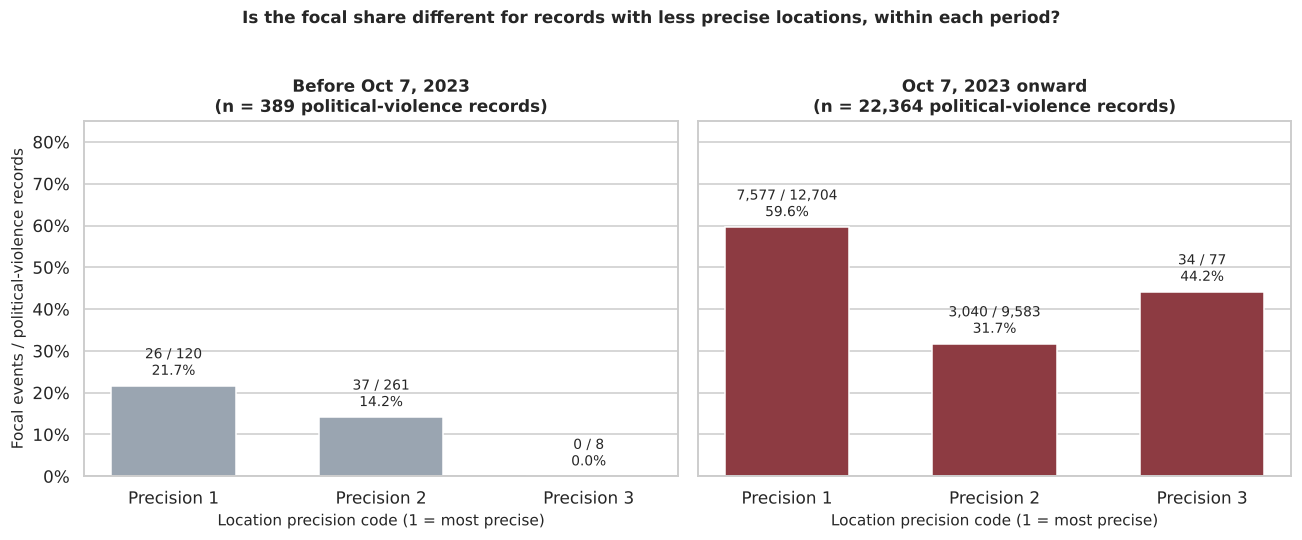

Oct 7 onward: focal share by district and precision (precision 3 omitted, n < 70 in every district)


,"n, precision 1","n, precision 2","focal share, precision 1","focal share, precision 2"
admin2,,,,
Deir El Balah,2537,1823,0.672,0.315
Gaza City,4095,2740,0.617,0.326
Khan Yunis,2867,2028,0.555,0.346
North Gaza,1845,1431,0.562,0.202
Rafah,1360,1560,0.529,0.373


Oct 7 onward, Explosions/Remote violence only


,n,focal,focal_share
geo_precision,,,
1,11523,7222,0.627
2,8414,2637,0.313
3,41,8,0.195


In [8]:
t6 = (political.groupby(["period", "geo_precision"], observed=True)
      .agg(n=("event_id_cnty", "size"), focal=("focal_event", "sum")))
t6["focal_share"] = t6.focal / t6.n
display(t6.round({"focal_share": 3}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, period, col in zip(axes, [BEFORE, AFTER], [C_GREY, C_FOCAL]):
    d = t6.loc[period].reindex([1, 2, 3])
    bars = ax.bar([f"Precision {k}" for k in d.index], d.focal_share, color=col, width=0.6)
    for b, (_, r) in zip(bars, d.iterrows()):
        if r.n < 30:
            b.set_hatch("//"); b.set_alpha(0.55)
        ax.text(b.get_x() + b.get_width() / 2, r.focal_share + 0.015,
                f"{r.focal:,.0f} / {r.n:,.0f}\n{r.focal_share:.1%}", ha="center", va="bottom", fontsize=9)
    ax.set_ylim(0, 0.85)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set_xlabel("Location precision code (1 = most precise)")
    ax.set_title(f"{period}\n(n = {int(d.n.sum()):,} political-violence records)")
axes[0].set_ylabel("Focal events / political-violence records")
fig.suptitle("Is the focal share different for records with less precise locations, within each period?",
             fontsize=11, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# Robustness: does the precision 1 vs 2 gap survive inside each district and inside Explosions? (Oct 7 onward)
post_pol = political[political.period == AFTER]
by_district = post_pol[post_pol.geo_precision.isin([1, 2])].groupby(["admin2", "geo_precision"], observed=True).focal_event.agg(["size", "mean"]).unstack()
by_district.columns = [f"{'n' if a == 'size' else 'focal share'}, precision {b}" for a, b in by_district.columns]
print("Oct 7 onward: focal share by district and precision (precision 3 omitted, n < 70 in every district)")
display(by_district.round(3))
expl = post_pol[post_pol.event_type == "Explosions/Remote violence"]
print("Oct 7 onward, Explosions/Remote violence only")
display(expl.groupby("geo_precision", observed=True).focal_event.agg(n="size", focal="sum", focal_share="mean").round(3))

**Interpretation.** From Oct 7 onward the focal share is 59.6% for precision 1 (7,577 of 12,704) and 31.7% for precision 2 (3,040 of 9,583); before Oct 7 the same ordering appears at lower levels (21.7% vs. 14.2%), and precision 3 has too few records to read (8 and 77) (BQ5). The precision 1 vs. 2 gap holds inside all five districts (for example Deir El Balah 67.2% vs. 31.5%) and within Explosions (62.7% vs. 31.3%), so neither district nor event type explains it alone; these fields cannot tell us whether it reflects documentation practice, coverage or something else, which makes the precision-1 sensitivity run in Phase 4 important.

### 3.6 Recorded actor labels and sub-event types among focal events (BQ2)

**Question.** Which recorded `actor1` labels appear in focal events, and with which sub-event types? The focal rule requires "Civilians (Palestine)" in one actor field, so we first check where that label sits. Labels describe ACLED coding and are not verified roles. The five most frequent `actor1` labels are shown individually and the rest are grouped, with the number of grouped labels stated. Original labels are not merged.

Focal events: 10714
actor2 == 'Civilians (Palestine)': 10714 | actor2 blank: 0 | actor1 == 'Civilians (Palestine)': 0
Distinct actor1 labels among focal events: 14

Event type vs. sub-event type among focal events


event_type,Explosions/Remote violence,Violence against civilians
sub_event_type,,
Abduction/forced disappearance,0,15
Air/drone strike,8420,0
Attack,0,792
Remote explosive/landmine/IED,44,0
Sexual violence,0,1
Shelling/artillery/missile attack,1442,0


sub_event_type,Air/drone strike,Shelling/artillery/missile attack,Attack,Remote explosive/landmine/IED,Abduction/forced disappearance,Sexual violence
"Military Forces of Israel (2022-) (n = 10,493)",8392,1436,606,43,15,1
Sahm Unit (n = 90),0,0,90,0,0,0
Military Forces of Israel (2021-2022) (n = 36),26,2,8,0,0,0
Hamas Movement (n = 36),0,1,35,0,0,0
Unidentified Armed Group (Palestine) (n = 28),1,1,25,1,0,0
All other actor1 labels (9 labels) (n = 31),1,2,28,0,0,0


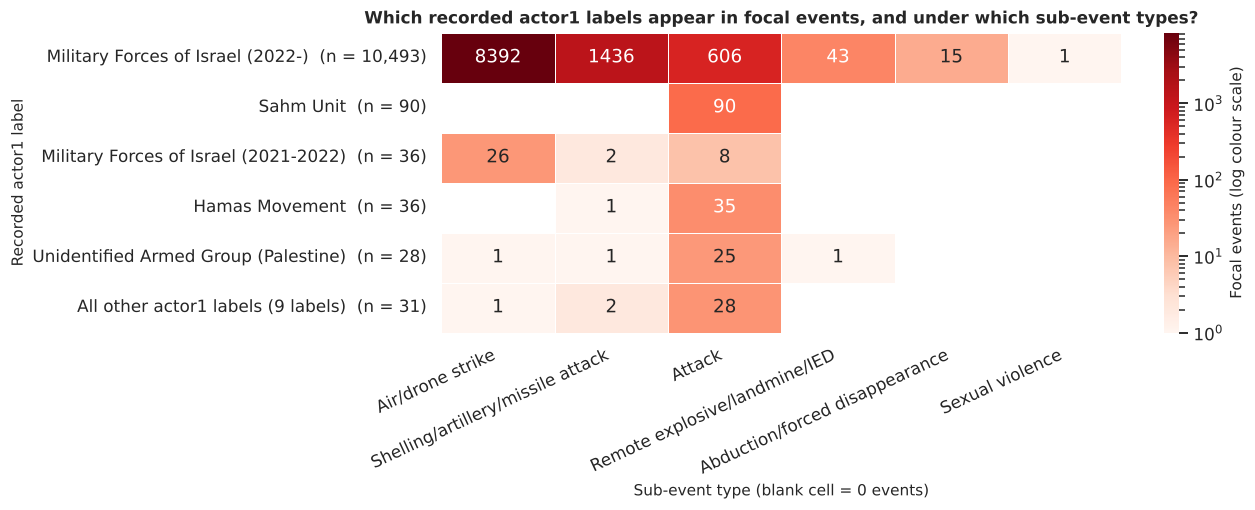

In [9]:
focal = master.loc[master.focal_event].copy()
print("Focal events:", len(focal))
print("actor2 == 'Civilians (Palestine)':", int((focal.actor2 == "Civilians (Palestine)").sum()),
      "| actor2 blank:", int(focal.actor2.isna().sum()),
      "| actor1 == 'Civilians (Palestine)':", int((focal.actor1 == "Civilians (Palestine)").sum()))
print("Distinct actor1 labels among focal events:", focal.actor1.nunique())
print("\nEvent type vs. sub-event type among focal events")
display(pd.crosstab(focal.sub_event_type, focal.event_type))

ct = pd.crosstab(focal.actor1, focal.sub_event_type)
totals = ct.sum(axis=1).sort_values(ascending=False)
TOP_N = 5
keep = totals.index[:TOP_N]
ct_show = ct.loc[keep].copy()
ct_show.loc[f"All other actor1 labels ({len(totals) - TOP_N} labels)"] = ct.loc[~ct.index.isin(keep)].sum()
ct_show = ct_show[ct_show.sum().sort_values(ascending=False).index]
ct_show.index = [f"{i}  (n = {n:,})" for i, n in ct_show.sum(axis=1).items()]
display(ct_show)

fig, ax = plt.subplots(figsize=(12, 4.8))
sns.heatmap(ct_show.where(ct_show > 0), annot=ct_show.astype(int).astype(str), fmt="",
            cmap="Reds", norm=LogNorm(vmin=1, vmax=ct_show.to_numpy().max()),
            linewidths=0.5, linecolor="white", cbar_kws={"label": "Focal events (log colour scale)"}, ax=ax)
ax.grid(False)
ax.set_xlabel("Sub-event type (blank cell = 0 events)")
ax.set_ylabel("Recorded actor1 label")
ax.set_title("Which recorded actor1 labels appear in focal events, and under which sub-event types?")
plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
plt.tight_layout()
plt.show()

**Interpretation.** All 10,714 focal events carry "Civilians (Palestine)" in `actor2` and none in `actor1`, so the actor view rests on `actor1`, where "Military Forces of Israel (2022-)" appears in 10,493 events (97.9%), mostly under Air/drone strike (8,392) and Shelling/artillery/missile attack (1,436); the Attack sub-event type (792 events) is where the other labels appear, such as Sahm Unit (90) and Hamas Movement (35) (BQ2). These are ACLED's recorded labels, not verified roles, and one label dominates so heavily that the other rows are hard to compare, so any statement about who did what needs the event notes.

## 4. Multivariate, grouped and temporal analysis

The unit of analysis changes in this section. Chart 7 uses event records, Charts 8 and 10 use district-weeks, and Charts 9 and 11 use Gaza-wide weeks. The district-week table leaves out the 4 events with no district (3 of them focal), so its focal total (10,648) is 3 below the Gaza-wide total (10,651).

### 4.1 Event type, period and focal status together (BQ1, BQ2)

**Question.** Did the mix of recorded event types change between the periods, and did the focal share *within* a type change? The left panel shows composition (each bar sums to 100% of that period's political-violence records). The right panel shows the focal share for the only two event types that contain focal events. Counts for every type, including the very small ones, are in the table.

records  focal  focal_share
period             event_type                                             
Before Oct 7, 2023 Battles                          55      0        0.000
                   Explosions/Remote violence      298     39        0.131
                   Protests                          7      0        0.000
                   Riots                             5      0        0.000
                   Violence against civilians       24     24        1.000
Oct 7, 2023 onward Battles                        1593      0        0.000
                   Explosions/Remote violence    19978   9867        0.494
                   Riots                             3      0        0.000
                   Violence against civilians      790    784        0.992

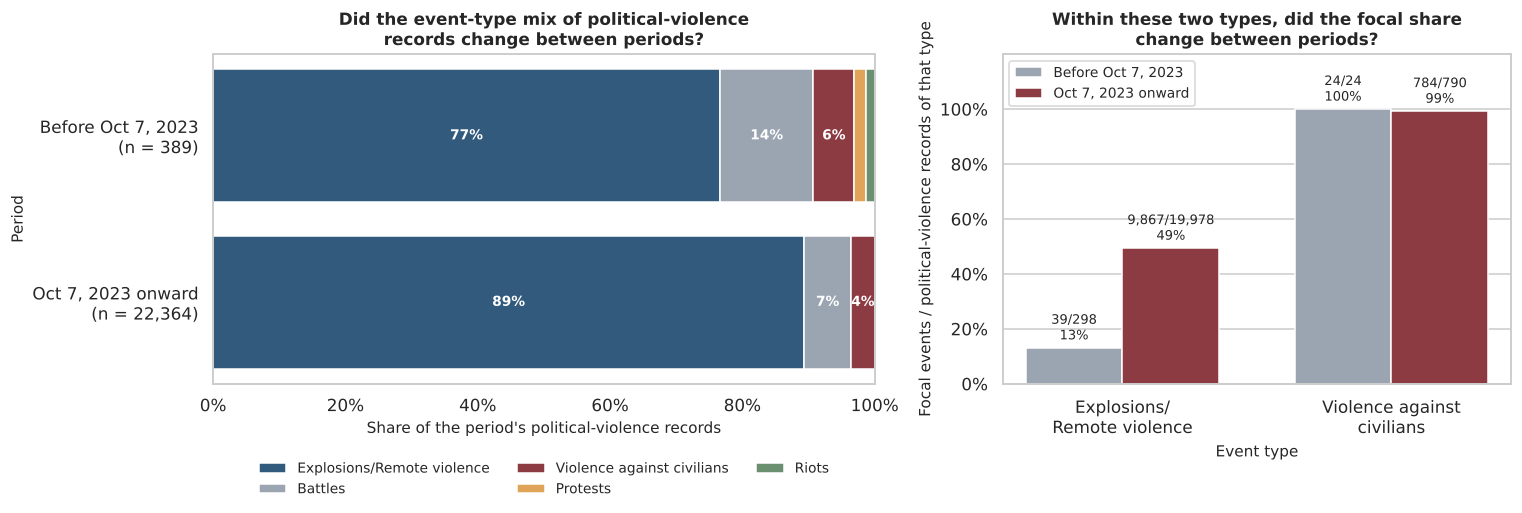

In [10]:
type_order = ["Explosions/Remote violence", "Battles", "Violence against civilians", "Protests", "Riots"]
t7 = (political.groupby(["period", "event_type"])
      .agg(records=("event_id_cnty", "size"), focal=("focal_event", "sum")))
t7["focal_share"] = t7.focal / t7.records
display(t7.round({"focal_share": 3}))

comp = (pd.crosstab(political.period, political.event_type)
        .reindex(index=[BEFORE, AFTER], columns=type_order, fill_value=0))
comp_share = comp.div(comp.sum(axis=1), axis=0)
type_colors = dict(zip(type_order, ["#315A7D", "#9AA5B1", "#8D3B42", "#E0A458", "#6B8F71"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
for i, period in enumerate([BEFORE, AFTER]):
    left = 0
    for t in type_order:
        wdt = comp_share.loc[period, t]
        ax.barh(i, wdt, left=left, color=type_colors[t], edgecolor="white", label=t if i == 0 else None)
        if wdt >= 0.03:
            ax.text(left + wdt / 2, i, f"{wdt:.0%}", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
        left += wdt
ax.set_yticks([0, 1])
ax.set_yticklabels([f"{p}\n(n = {int(comp.loc[p].sum()):,})" for p in [BEFORE, AFTER]])
ax.invert_yaxis(); ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Share of the period's political-violence records")
ax.set_ylabel("Period")
ax.set_title("Did the event-type mix of political-violence\nrecords change between periods?")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)

ax = axes[1]
two = ["Explosions/Remote violence", "Violence against civilians"]
xs = np.arange(len(two)); w = 0.36
for j, (period, col) in enumerate([(BEFORE, C_GREY), (AFTER, C_FOCAL)]):
    vals = [t7.loc[(period, t), "focal_share"] for t in two]
    bars = ax.bar(xs + (j - 0.5) * w, vals, w, color=col, label=period)
    for b, t in zip(bars, two):
        r = t7.loc[(period, t)]
        ax.text(b.get_x() + b.get_width() / 2, r.focal_share + 0.015, f"{r.focal:,.0f}/{r.records:,.0f}\n{r.focal_share:.0%}",
                ha="center", va="bottom", fontsize=8.5)
ax.set_xticks(xs); ax.set_xticklabels(["Explosions/\nRemote violence", "Violence against\ncivilians"])
ax.set_ylim(0, 1.2); ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Event type")
ax.set_ylabel("Focal events / political-violence records of that type")
ax.set_title("Within these two types, did the focal share\nchange between periods?")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Interpretation.** Explosions/Remote violence grows from 77% (298 of 389) to 89% (19,978 of 22,364) of political-violence records while Battles fall from 14% to 7%; within types, the focal share of Explosions rises from 13.1% (39 of 298) to 49.4% (9,867 of 19,978), while Violence against civilians stays near 100% in both periods (24 of 24, then 784 of 790) (BQ1, BQ2). The rise in the overall focal share is therefore carried by Explosions/Remote violence, but its earlier base of 298 records is small and Protests and Riots are too rare (12 records before, 3 after) to show.

### 4.2 Actor, sub-event type and district at a glance: see Chart 6

The actor view is already covered by Chart 6, so we do not repeat it here.

### 4.3 District by week: where and when are focal counts high? (BQ4)

**Question.** Which districts have persistent or sudden high-count weeks? Every district has a row for every week; weeks with no recorded focal events stay in the grid with value 0. The final partial week is greyed out and left out of the colour scale. This chart shows counts, which reflect volume; Chart 10 shows shares.

,focal,political,median_weekly_focal,max_weekly_focal,weeks_without_political,focal_share
admin2,,,,,,
Gaza City,3451,6903,30.0,102,0,0.500
Khan Yunis,2292,4898,21.5,64,0,0.468
Deir El Balah,2278,4361,22.0,44,0,0.522
North Gaza,1325,3277,9.0,61,3,0.404
Rafah,1302,2921,10.0,31,0,0.446


Highest district-weeks by focal count


,admin2,week_start,focal_events,political_events,focal_share
108,Gaza City,2023-11-04,102,156,0.654
107,Gaza City,2023-10-28,92,131,0.702
205,Gaza City,2025-09-13,84,113,0.743
204,Gaza City,2025-09-06,79,97,0.814
206,Gaza City,2025-09-20,77,131,0.588
106,Gaza City,2023-10-21,75,100,0.750


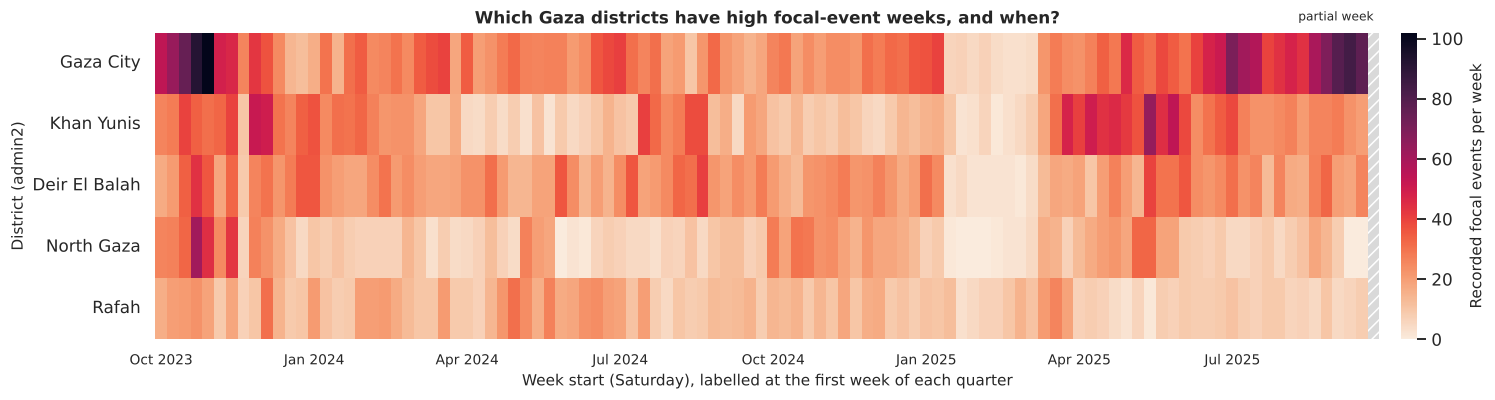

In [11]:
dw = district_week.copy()
dist_order = dw.groupby("admin2").focal_events.sum().sort_values(ascending=False).index
heat = dw.pivot(index="admin2", columns="week_start", values="focal_events").loc[dist_order].astype(float)
complete = dw.drop_duplicates("week_start").set_index("week_start").complete_week.reindex(heat.columns).to_numpy()
heat_plot = heat.copy()
heat_plot.loc[:, ~complete] = np.nan  # keep the partial week out of the colour scale

dist_summary = dw.groupby("admin2").agg(focal=("focal_events", "sum"), political=("political_events", "sum"),
                                         median_weekly_focal=("focal_events", "median"),
                                         max_weekly_focal=("focal_events", "max"),
                                         weeks_without_political=("political_events", lambda s: int((s == 0).sum()))).loc[dist_order]
dist_summary["focal_share"] = dist_summary.focal / dist_summary.political
display(dist_summary.round({"focal_share": 3}))
print("Highest district-weeks by focal count")
display(dw.nlargest(6, "focal_events")[["admin2", "week_start", "focal_events", "political_events", "focal_share"]].round({"focal_share": 3}))

fig, ax = plt.subplots(figsize=(15, 3.8))
sns.heatmap(heat_plot, cmap="rocket_r", xticklabels=False, cbar_kws={"label": "Recorded focal events per week", "pad": 0.015}, ax=ax)
for j in np.where(~complete)[0]:
    ax.add_patch(Rectangle((j, 0), 1, len(heat), facecolor="#D9D9D9", edgecolor="none", hatch="///"))
    ax.text(j + 0.5, -0.15, "partial week", ha="right", va="bottom", fontsize=8)
first_of_quarter = ~pd.Series(pd.PeriodIndex(heat.columns, freq="Q")).duplicated().to_numpy()
pos = np.where(first_of_quarter)[0]
ax.set_xticks(pos + 0.5)
ax.set_xticklabels(heat.columns[pos].strftime("%b %Y"), rotation=0, fontsize=9)
ax.grid(False)
ax.set_xlabel("Week start (Saturday), labelled at the first week of each quarter")
ax.set_ylabel("District (admin2)")
ax.set_title("Which Gaza districts have high focal-event weeks, and when?")
plt.tight_layout()
plt.show()

**Interpretation.** Gaza City holds the six highest district-weeks (102 focal events in the week of Nov 4, 2023, and 77 to 84 in each of three weeks in September 2025), and every district turns pale in the same stretch of early 2025 (BQ4). Counts reflect volume as well as focus (Gaza City records 6,903 political-violence records against 2,921 in Rafah), the final partial week is excluded, and a zero cell means zero recorded events, so Chart 10 is needed to read the share.

### 4.4 Gaza-wide weekly counts and share (BQ4)

**Question.** How do weekly focal counts and the focal share move over time, and are the two moving together? The top panel shows counts, the bottom panel shows the share, on the same week axis. The hollow marker is the incomplete final week. The shaded band marks the five weeks with the lowest focal counts; we describe them and do not explain them, because the files hold no source for the cause.

Five lowest focal-count weeks: ['2025-01-25', '2025-02-01', '2025-02-08', '2025-02-15', '2025-02-22']


,week_start,recorded_events,political_events,focal_events,focal_share
68,2025-01-25,31,27,17,0.630
69,2025-02-01,23,22,15,0.682
70,2025-02-08,42,33,23,0.697
71,2025-02-15,43,40,15,0.375
72,2025-02-22,42,38,20,0.526


Mean weekly focal events by quarter (complete weeks)


,focal_events,political_events
week_start,,
2023Q4,152.6,290.6
2024Q1,96.5,265.6
2024Q2,84.5,228.5
2024Q3,91.9,212.5
2024Q4,91.6,201.5
2025Q1,54.2,100.7
2025Q2,126.7,221.8
2025Q3,124.8,204.7


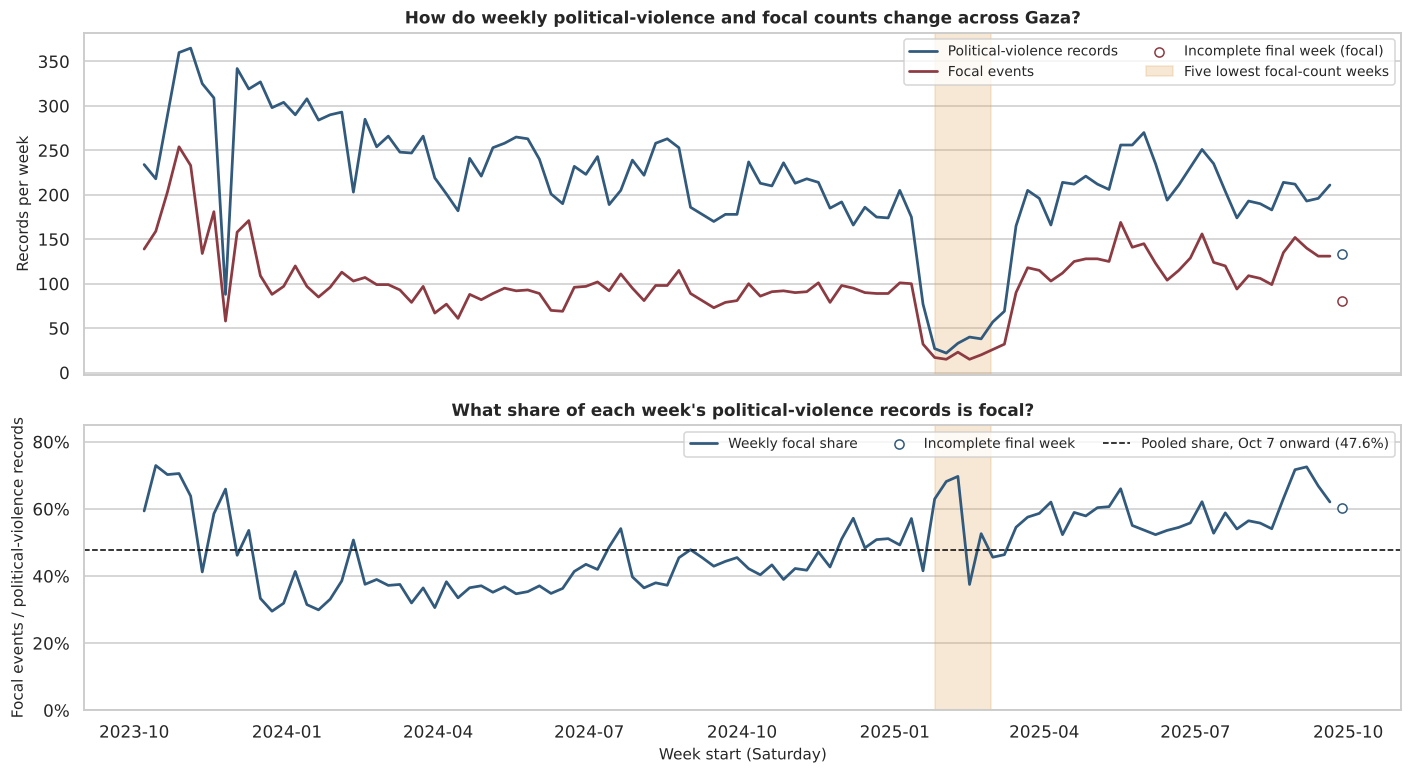

In [12]:
gw = gaza_week.sort_values("week_start").copy()
low5 = gw.nsmallest(5, "focal_events")
low_span = (low5.week_start.min(), low5.week_end.max())
partial = gw[~gw.complete_week]
full = gw[gw.complete_week]
post_share = master.loc[master.period == AFTER, "focal_event"].sum() / political.loc[political.period == AFTER].shape[0]
print("Five lowest focal-count weeks:", [d.date().isoformat() for d in sorted(low5.week_start)])
display(low5.sort_values("week_start")[["week_start", "recorded_events", "political_events", "focal_events", "focal_share"]].round({"focal_share": 3}))
print("Mean weekly focal events by quarter (complete weeks)")
display(full.groupby(full.week_start.dt.to_period("Q"))[["focal_events", "political_events"]].mean().round(1))

fig, axes = plt.subplots(2, 1, figsize=(13, 7.2), sharex=True, gridspec_kw={"height_ratios": [1.2, 1]})
ax = axes[0]
ax.plot(full.week_start, full.political_events, color=C_OTHER, lw=1.8, label="Political-violence records")
ax.plot(full.week_start, full.focal_events, color=C_FOCAL, lw=1.8, label="Focal events")
ax.scatter(partial.week_start, partial.focal_events, facecolor="white", edgecolor=C_FOCAL, zorder=5, label="Incomplete final week (focal)")
ax.scatter(partial.week_start, partial.political_events, facecolor="white", edgecolor=C_OTHER, zorder=5)
ax.axvspan(*low_span, color="#E0A458", alpha=0.25, label="Five lowest focal-count weeks")
ax.set_ylabel("Records per week")
ax.set_title("How do weekly political-violence and focal counts change across Gaza?")
ax.legend(loc="upper right", ncol=2)

ax = axes[1]
ax.plot(full.week_start, full.focal_share, color=C_OTHER, lw=1.8, label="Weekly focal share")
ax.scatter(partial.week_start, partial.focal_share, facecolor="white", edgecolor=C_OTHER, zorder=5, label="Incomplete final week")
ax.axhline(post_share, color="black", ls="--", lw=1, label=f"Pooled share, Oct 7 onward ({post_share:.1%})")
ax.axvspan(*low_span, color="#E0A458", alpha=0.25)
ax.set_ylim(0, 0.85)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylabel("Focal events / political-violence records")
ax.set_xlabel("Week start (Saturday)")
ax.set_title("What share of each week's political-violence records is focal?")
ax.legend(loc="upper right", ncol=3)
plt.tight_layout()
plt.show()

**Interpretation.** Weekly focal events peak at 254 in the week of Oct 28, 2023, run between 61 and 120 through 2024, fall to 15 to 23 in the five lowest weeks (week starts Jan 25 to Feb 22, 2025), and average about 125 per week in Q2 and Q3 2025; the focal share ranges from 30% to 73% and sits above the pooled 47.6% in 17% of 2024 weeks but 89% of 2025 weeks (BQ4). The share does not fall with the counts in the low weeks (38% to 70%), so counts and shares must be read separately, and with only 22 to 40 political-violence records in those weeks the share is volatile; the cause of the dip cannot be read from these files.

### 4.5 District focal share with denominators (BQ4)

**Question.** After accounting for how much political violence each district records, do districts differ in focal share, and is the share stable week to week? Each panel shows the weekly share (thin line, gaps where the denominator is zero), a 4-week pooled share (focal events over political-violence records in the same four weeks), and the district's overall share (dashed). The incomplete final week is left out. The panel titles and table carry the denominators.

,focal,political,undefined_weeks,overall_share
admin2,,,,
Gaza City,3411,6825,0,0.500
Khan Yunis,2278,4876,0,0.467
Deir El Balah,2257,4335,0,0.521
North Gaza,1325,3277,2,0.404
Rafah,1297,2914,0,0.445


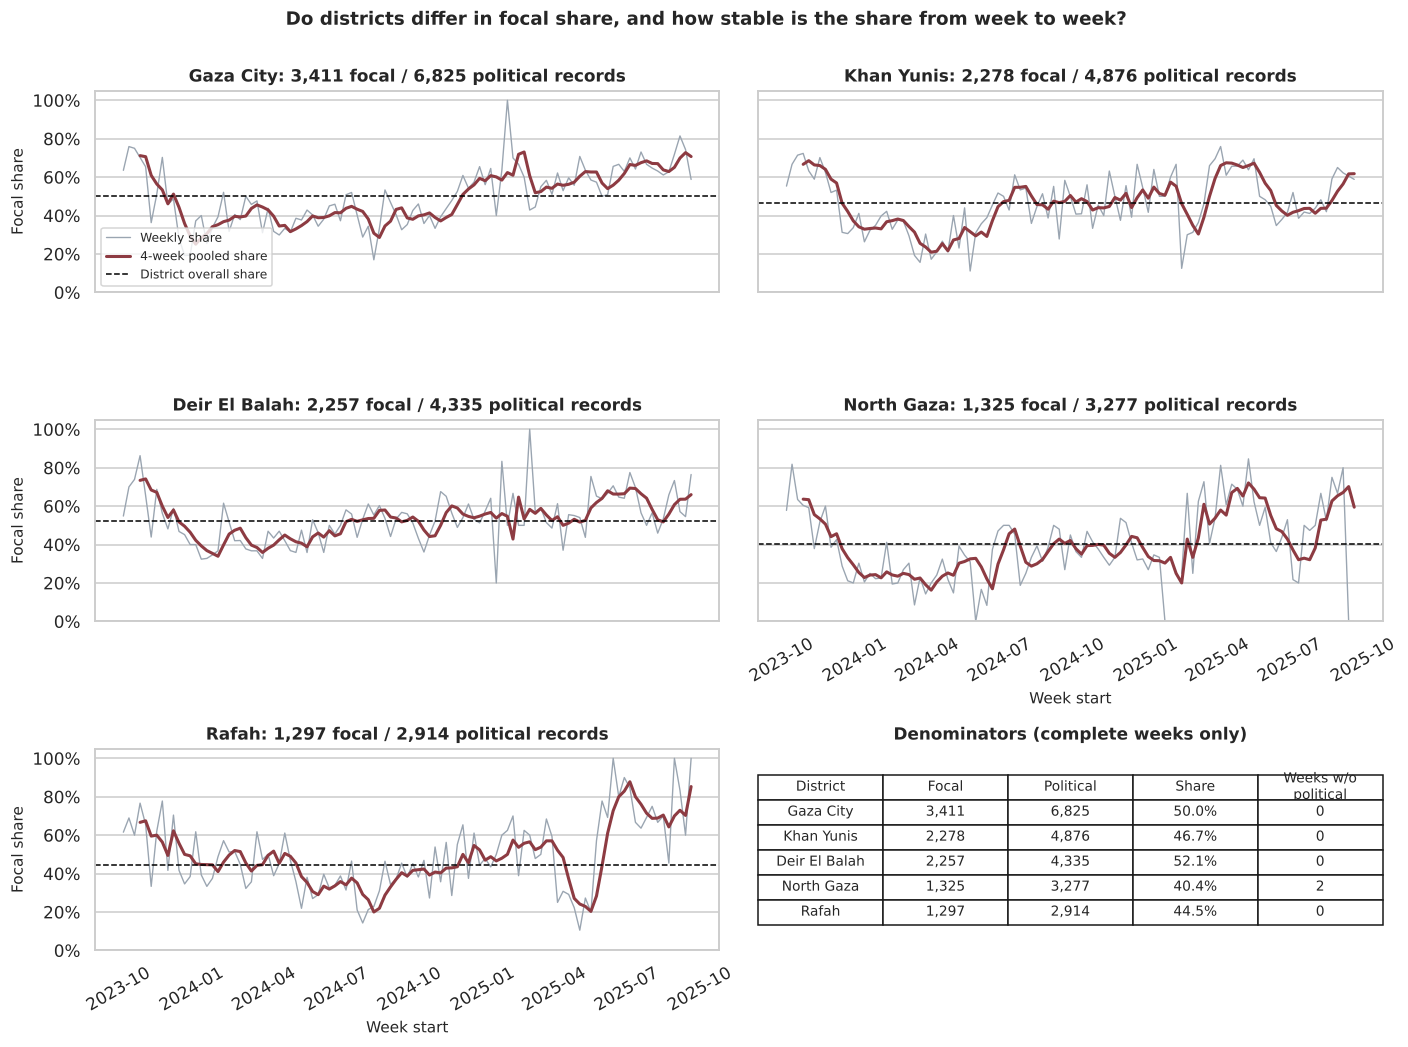

In [13]:
dwc = district_week[district_week.complete_week].sort_values(["admin2", "week_start"]).copy()
roll = lambda col: dwc.groupby("admin2")[col].transform(lambda s: s.rolling(4, min_periods=4).sum())
dwc["focal_4w"], dwc["political_4w"] = roll("focal_events"), roll("political_events")
dwc["share_4w"] = dwc.focal_4w / dwc.political_4w.where(dwc.political_4w > 0)

tbl = (dwc.groupby("admin2").agg(focal=("focal_events", "sum"), political=("political_events", "sum"),
                                  undefined_weeks=("focal_share", lambda s: int(s.isna().sum()))).loc[dist_order])
tbl["overall_share"] = tbl.focal / tbl.political
display(tbl.round({"overall_share": 3}))

fig, axes = plt.subplots(3, 2, figsize=(13, 9.5), sharex=True, sharey=True)
axes = axes.ravel()
for ax, dname in zip(axes, dist_order):
    d = dwc[dwc.admin2 == dname]
    ax.plot(d.week_start, d.focal_share, color=C_GREY, lw=0.9, label="Weekly share")
    ax.plot(d.week_start, d.share_4w, color=C_FOCAL, lw=2, label="4-week pooled share")
    ax.axhline(tbl.loc[dname, "overall_share"], color="black", ls="--", lw=1, label="District overall share")
    ax.set_title(f"{dname}: {tbl.loc[dname, 'focal']:,.0f} focal / {tbl.loc[dname, 'political']:,.0f} political records")
    ax.set_ylim(0, 1.05)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.tick_params(axis="x", labelrotation=30)
axes[0].legend(loc="lower left", fontsize=8)
axes[3].tick_params(axis="x", labelbottom=True, labelrotation=30)
for ax in axes[-3:-1]:
    ax.set_xlabel("Week start")
for ax in axes[::2][:3]:
    ax.set_ylabel("Focal share")
# Last panel: the denominators as a table
ax = axes[-1]; ax.axis("off")
cell = [[i, f"{r.focal:,.0f}", f"{r.political:,.0f}", f"{r.overall_share:.1%}", int(r.undefined_weeks)] for i, r in tbl.iterrows()]
t = ax.table(cellText=cell, colLabels=["District", "Focal", "Political", "Share", "Weeks w/o\npolitical"], loc="center", cellLoc="center")
t.auto_set_font_size(False); t.set_fontsize(9); t.scale(1, 1.6)
ax.set_title("Denominators (complete weeks only)")
fig.suptitle("Do districts differ in focal share, and how stable is the share from week to week?", fontsize=12, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

**Interpretation.** Overall focal share runs from 40.4% in North Gaza (1,325 of 3,277) to 52.1% in Deir El Balah (2,257 of 4,335), with Gaza City at 50.0% (3,411 of 6,825); the 4-week share starts high in every district, falls below the district average for most of 2024 (Gaza City is above it in only 8% of 2024 weeks), and from June 2025 Gaza City and Rafah stay above it in every week (BQ4). Rafah swings most (20.0% in the week of Aug 17, 2024 to 87.8% on Jul 5, 2025), and weekly district shares rest on small denominators (North Gaza has 2 weeks with no political-violence records), so single-week spikes in share should not be over-read.

### 4.6 Correlation and association (BQ4, BQ5)

**Question.** Which weekly measures move together, and which categorical fields are associated? Two different measures are needed because the variable types differ.

- **Left, Spearman rank correlation** between weekly Gaza-wide measures (complete weeks only). † marks pairs that are related by construction (a subset or a denominator relationship, or overlapping windows), so a high value there is expected and says little. ‡ marks a variable correlated with its own earlier values (serial dependence). The sample size is lower for the lag columns because early weeks have no eligible history.
- **Right, Cramér's V** between categorical fields of political-violence records (0 = no association, 1 = perfect). Sub-event type is nested inside event type, so that pair is 1.0 by definition. V can be inflated when many cells are sparse, so the share of sparse cells is shown below the chart.

Neither measure shows cause.

Weekly Spearman: 103 complete weeks; pairwise n ranges from 99 to 103


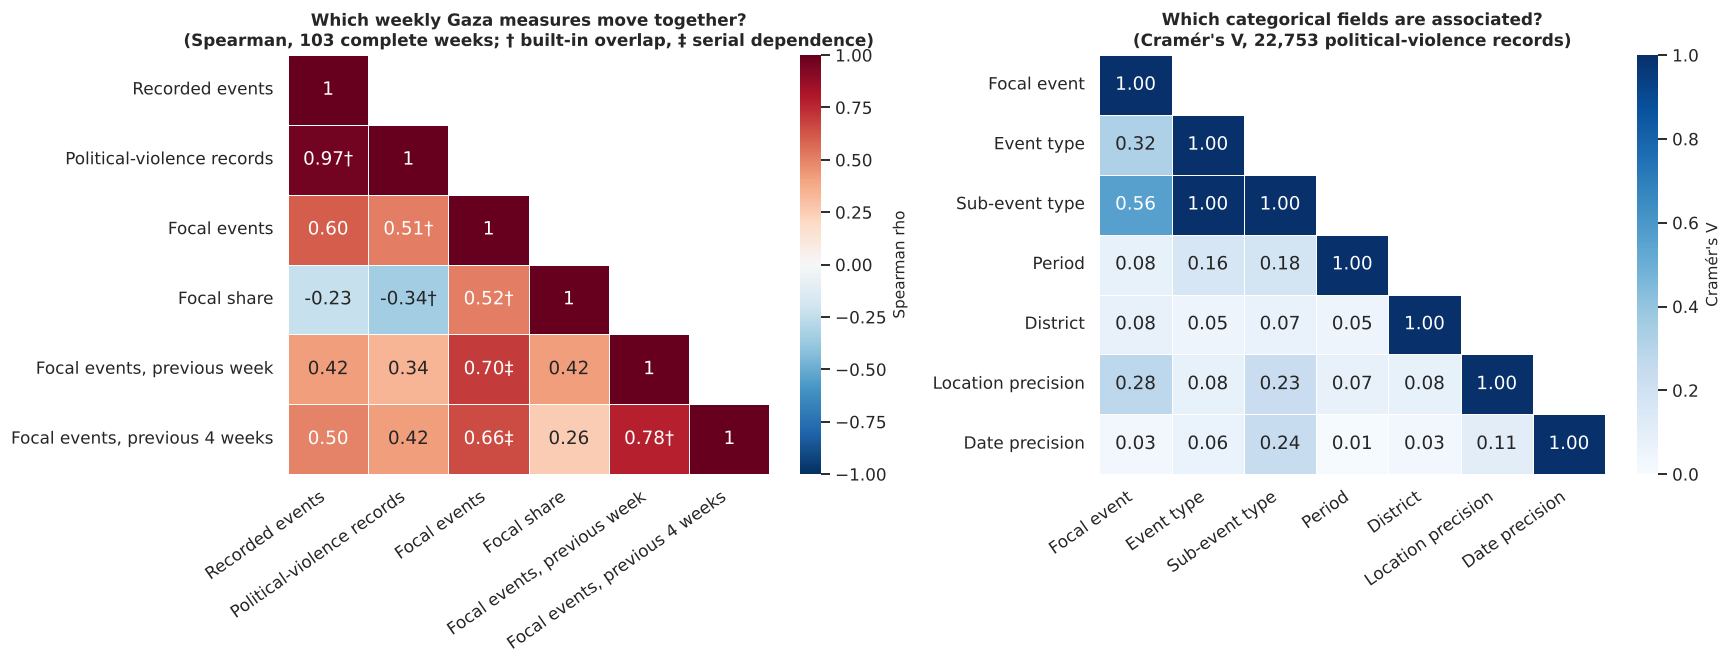

Share of contingency-table cells with expected count < 5 (sparse cells inflate V)


,Focal event,Event type,Sub-event type,Period,District,Location precision,Date precision
Focal event,,,,,,,
Event type,40.0,,,,,,
Sub-event type,45.0,67.0,,,,,
Period,0.0,20.0,41.0,,,,
District,0.0,40.0,55.0,0.0,,,
Location precision,0.0,47.0,55.0,17.0,0.0,,
Date precision,17.0,40.0,61.0,33.0,33.0,33.0,


In [14]:
# ---- Left: Spearman on weekly Gaza-wide numbers (complete weeks only) ----
wk_cols = ["recorded_events", "political_events", "focal_events", "focal_share", "previous_week_focal", "previous_four_weeks_focal"]
wk_lab = {"recorded_events": "Recorded events", "political_events": "Political-violence records", "focal_events": "Focal events",
          "focal_share": "Focal share", "previous_week_focal": "Focal events, previous week", "previous_four_weeks_focal": "Focal events, previous 4 weeks"}
wk = gaza_week.loc[gaza_week.complete_week, wk_cols]
rho = wk.corr(method="spearman")
n_pair = wk.notna().astype(int).T.dot(wk.notna().astype(int))
mechanical = [{"recorded_events", "political_events"}, {"political_events", "focal_events"},
              {"focal_events", "focal_share"}, {"political_events", "focal_share"},
              {"previous_week_focal", "previous_four_weeks_focal"}]
serial = [{"focal_events", "previous_week_focal"}, {"focal_events", "previous_four_weeks_focal"}]
def mark(a, b):
    s = {a, b}
    return "†" if s in mechanical else ("‡" if s in serial else "")
annot_r = pd.DataFrame([[f"{rho.loc[a, b]:.2f}{mark(a, b)}" if a != b else "1" for b in wk_cols] for a in wk_cols], index=wk_cols, columns=wk_cols)
print(f"Weekly Spearman: {len(wk)} complete weeks; pairwise n ranges from {int(n_pair.to_numpy().min())} to {int(n_pair.to_numpy().max())}")

# ---- Right: Cramér's V (plain, uncorrected) on political-violence records ----
def cramers_v(a, b):
    ok = a.notna() & b.notna()
    ct = pd.crosstab(a[ok].astype(str), b[ok].astype(str))
    if min(ct.shape) < 2:
        return np.nan, np.nan
    chi2, _, _, expected = chi2_contingency(ct, correction=False)
    return np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1))), (expected < 5).mean()

cat_vars = {"Focal event": political.focal_event, "Event type": political.event_type, "Sub-event type": political.sub_event_type,
            "Period": political.period, "District": political.admin2, "Location precision": political.geo_precision,
            "Date precision": political.time_precision}
names = list(cat_vars)
V = pd.DataFrame(np.nan, index=names, columns=names); sparse = V.copy()
for i, a in enumerate(names):
    for b in names[: i + 1]:
        if a == b:
            V.loc[a, b] = 1.0
        else:
            V.loc[a, b], sparse.loc[a, b] = cramers_v(cat_vars[a], cat_vars[b])

fig, axes = plt.subplots(1, 2, figsize=(16, 6.2), gridspec_kw={"width_ratios": [1, 1.05]})
sns.heatmap(rho, mask=np.triu(np.ones_like(rho, dtype=bool), k=1), annot=annot_r, fmt="", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            linewidths=0.5, linecolor="white", cbar_kws={"label": "Spearman rho"}, ax=axes[0])
for a_ in axes:
    a_.grid(False)
axes[0].set_xticklabels([wk_lab[c] for c in wk_cols], rotation=35, ha="right")
axes[0].set_yticklabels([wk_lab[c] for c in wk_cols], rotation=0)
axes[0].set_title(f"Which weekly Gaza measures move together?\n(Spearman, {len(wk)} complete weeks; † built-in overlap, ‡ serial dependence)")
sns.heatmap(V, mask=np.triu(np.ones_like(V, dtype=bool), k=1), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            linewidths=0.5, linecolor="white", cbar_kws={"label": "Cramér's V"}, ax=axes[1])
axes[1].set_xticklabels(names, rotation=35, ha="right"); axes[1].set_yticklabels(names, rotation=0)
axes[1].set_title(f"Which categorical fields are associated?\n(Cramér's V, {len(political):,} political-violence records)")
plt.tight_layout()
plt.show()

print("Share of contingency-table cells with expected count < 5 (sparse cells inflate V)")
display((sparse * 100).round(0).fillna("").astype(str).replace({"nan": ""}))

**Interpretation.** Weekly focal events move with recorded events (rho = 0.60) and with their own previous week (0.70) and previous four weeks (0.66), which supports using prior-week history as a feature in Phase 4 (BQ4); among categorical fields, focal status is moderately associated with sub-event type (V = 0.56), event type (0.32) and location precision (0.28) but weakly with period and district (0.08 each). Pairs marked † are related by construction (for example 0.97 between recorded events and political-violence records) and say little, the period value is held down by the very unequal group sizes (389 vs. 22,364 records), V is inflated where cells are sparse (see the table), and none of this shows cause.

## 5. Handoff notes for teammates

The tables below are the inputs that the hypothesis-test and key-insight sections are most likely to reuse. They contain **counts, rates and diagnostics only**: no p-values or test conclusions, because those belong to the teammates who own Hypotheses A and B.

In [15]:
period_table = pd.crosstab(political.period, political.focal_event).reindex([BEFORE, AFTER])
period_table.columns = ["Not focal", "Focal"]
type_table = pd.crosstab(political.event_type, political.focal_event)
type_table.columns = ["Not focal", "Focal"]

print("Hypothesis A input: period x focal (political-violence records)")
display(period_table.assign(Total=period_table.sum(axis=1), Focal_share=(period_table.Focal / period_table.sum(axis=1)).round(3)))
print("Hypothesis B input: event type x focal (political-violence records)")
display(type_table.assign(Total=type_table.sum(axis=1), Focal_share=(type_table.Focal / type_table.sum(axis=1)).round(3)))

# Preflight diagnostics only (expected counts under independence); no test is run here
for name, tab in [("A: period x focal", period_table), ("B: event type x focal", type_table)]:
    expected = chi2_contingency(tab.to_numpy(), correction=False)[3]
    print(f"{name}: smallest expected count = {expected.min():.2f}; cells below 5 = {(expected < 5).sum()} of {expected.size}")

Hypothesis A input: period x focal (political-violence records)


,Not focal,Focal,Total,Focal_share
period,,,,
"Before Oct 7, 2023",326,63,389,0.162
"Oct 7, 2023 onward",11713,10651,22364,0.476


Hypothesis B input: event type x focal (political-violence records)


,Not focal,Focal,Total,Focal_share
event_type,,,,
Battles,1648,0,1648,0.000
Explosions/Remote violence,10370,9906,20276,0.489
Protests,7,0,7,0.000
Riots,8,0,8,0.000
Violence against civilians,6,808,814,0.993


A: period x focal: smallest expected count = 183.17; cells below 5 = 0 of 4
B: event type x focal: smallest expected count = 3.30; cells below 5 = 4 of 10


**Handoff notes (counts and diagnostics only; no tests are run here).**

- **Hypothesis A inputs.** Political-violence records by period: before Oct 7, 2023 = 389 (63 focal, 16.2%); Oct 7 onward = 22,364 (10,651 focal, 47.6%). The smallest expected count is 183.2, so the sparse-cell concern does not arise for this table. The periods are 644 and 725 days long, and the Cramér's V for period × focal in the matrix is 0.08.
- **Hypothesis B inputs.** Focal share by event type: Violence against civilians 808 of 814 (99.3%), Explosions/Remote violence 9,906 of 20,276 (48.9%), Battles 0 of 1,648, Protests 0 of 7, Riots 0 of 8. The smallest expected count is 3.30 and 4 of 10 cells are below 5 (the Protests and Riots rows), so an asymptotic p-value should be replaced by a Monte Carlo or exact procedure, as Phase 2 did. Cramér's V for event type × focal is 0.32. Because the focal rule requires a civilian actor label, this association is partly built into the coding and should be described that way.
- **For the insights writer.** (1) The focal share rise is carried by Explosions/Remote violence (13.1% to 49.4%). (2) Focal records report a fatality far more often than other Explosions records (69% vs. 8%) but not larger totals when they do. (3) The precision 1 vs. 2 gap (59.6% vs. 31.7% after Oct 7) holds inside every district and within Explosions, so the precision-1 sensitivity run is warranted. (4) Weekly focal counts show strong week-to-week persistence (rho 0.70 with the previous week) and a visible low stretch in Jan to Feb 2025 that all five districts share; both matter for the anomaly-detection baseline. (5) Gaza City holds the six highest district-weeks, but district shares are noisy on small weekly denominators.
- **Carry-forward cautions.** `actor2` is constant among focal events, and one `actor1` label covers 97.9% of them. The district-week table is 3 focal events short of the Gaza-wide total by design. The final week (starting Sep 27, 2025) is incomplete and is excluded from Charts 8 to 11 colour scales, lines and correlations; it is marked in Chart 9.